# **Setup & Data Loading**

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [9]:
platform_colors= {
    'TikTok': '#000000',
    'Instagram Reels': '#C13584',
    'YouTube Shorts': '#FF0000',
    'Snapchat Spotlight': '#FFFC00'
    }

In [10]:
data = pd.read_csv('/content/drive/MyDrive/short_form_brain_rot_cognitive_decay.csv')

# **BASIC DATA EXPLORATION**

In [11]:
data.shape

(9000, 19)

In [12]:
data.head(5)

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
0,ROT-00001,24,Female,Instagram Reels,2.4,5.1,11.8,9,70,7.8,4.0,5.9,74.1,7.4,11.1,3.6,37.6,49.4,Mild Attentional Strain
1,ROT-00002,48,Female,TikTok,4.0,11.1,5.4,10,90,6.1,2.9,6.8,71.6,6.9,9.6,4.8,34.7,47.7,Mild Attentional Strain
2,ROT-00003,34,Female,Instagram Reels,3.3,17.5,3.4,13,59,6.5,3.3,8.1,93.8,6.6,8.3,4.4,35.5,62.5,Mild Attentional Strain
3,ROT-00004,30,Male,Instagram Reels,3.6,11.8,5.1,7,57,6.9,2.2,7.3,84.5,6.7,8.8,4.4,36.0,56.3,Mild Attentional Strain
4,ROT-00005,19,Female,YouTube Shorts,1.9,17.3,3.5,4,30,7.2,3.5,6.2,110.2,9.3,7.1,3.8,18.0,73.5,Normal / Intact Focus


In [13]:
data.tail()

,participant_id,age,gender,primary_platform,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct,cognitive_decay_tier
8995,ROT-08996,27,Female,TikTok,10.1,4.9,12.2,28,180,4.6,10.0,14.4,8.0,2.5,32.0,10.0,89.2,5.3,Acute Brain Rot / Executive Burnout
8996,ROT-08997,19,Female,Instagram Reels,4.2,11.9,5.0,13,81,6.6,3.7,7.2,74.4,6.8,11.7,6.2,40.2,49.6,Mild Attentional Strain
8997,ROT-08998,51,Female,YouTube Shorts,4.9,16.9,3.6,18,100,5.9,3.6,8.4,93.2,7.2,8.2,6.1,39.5,62.1,Mild Attentional Strain
8998,ROT-08999,18,Female,TikTok,3.8,10.1,5.9,10,80,6.5,4.0,7.0,75.9,7.2,10.3,4.3,35.5,50.6,Mild Attentional Strain
8999,ROT-09000,46,Female,TikTok,5.3,9.5,6.3,14,109,7.2,3.4,9.9,68.0,7.0,10.9,5.0,46.3,45.3,Mild Attentional Strain


In [14]:
data.dtypes

,0
participant_id,object
age,int64
gender,object
primary_platform,object
daily_short_form_hours,float64
avg_clip_duration_sec,float64
swipes_per_minute,float64
scroll_sessions_day,int64
bedtime_scroll_min,int64
total_sleep_hours,float64


In [15]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9000 entries, 0 to 8999
Data columns (total 19 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   participant_id                9000 non-null   object 
 1   age                           9000 non-null   int64  
 2   gender                        9000 non-null   object 
 3   primary_platform              9000 non-null   object 
 4   daily_short_form_hours        9000 non-null   float64
 5   avg_clip_duration_sec         9000 non-null   float64
 6   swipes_per_minute             9000 non-null   float64
 7   scroll_sessions_day           9000 non-null   int64  
 8   bedtime_scroll_min            9000 non-null   int64  
 9   total_sleep_hours             9000 non-null   float64
 10  multitasking_score            9000 non-null   float64
 11  total_screen_time_hours       9000 non-null   float64
 12  sustained_attention_span_sec  9000 non-null   float64
 13  wor

# **Dirty data**

In [16]:
data_dirty = data.copy(deep=True)
np.random.seed(42)

numeric_cols = [
    "age", "daily_short_form_hours", "avg_clip_duration_sec",
    "swipes_per_minute", "scroll_sessions_day", "bedtime_scroll_min",
    "total_sleep_hours", "multitasking_score", "total_screen_time_hours",
    "sustained_attention_span_sec", "working_memory_score",
    "task_switch_latency_sec", "brain_fog_score",
    "dopamine_burnout_index", "attention_retention_pct"
]
numeric_cols = [col for col in numeric_cols if col in data_dirty.columns]

categorical_cols = [
    col for col in ["gender", "primary_platform"]
    if col in data_dirty.columns
]

for col in numeric_cols:
    rows = data_dirty.sample(frac=0.02, random_state=42).index
    data_dirty.loc[rows, col] = np.nan

for col in categorical_cols:
    rows = data_dirty.sample(frac=0.02, random_state=21).index
    data_dirty.loc[rows, col] = np.nan

if "age" in data_dirty.columns:
    data_dirty.loc[data_dirty.index[0], "age"] = 150

data_dirty = pd.concat(
    [data_dirty, data_dirty.iloc[[1, 2, 3]]],
    ignore_index=True
)

print("Original shape:", data.shape)
print("Dirty shape:", data_dirty.shape)
print("\nMissing values:\n", data_dirty.isnull().sum())
print("\nDuplicate rows:", data_dirty.duplicated().sum())


Original shape: (9000, 19)
Dirty shape: (9003, 19)

Missing values:
 participant_id                    0
age                             180
gender                          180
primary_platform                180
daily_short_form_hours          180
avg_clip_duration_sec           180
swipes_per_minute               180
scroll_sessions_day             180
bedtime_scroll_min              180
total_sleep_hours               180
multitasking_score              180
total_screen_time_hours         180
sustained_attention_span_sec    180
working_memory_score            180
task_switch_latency_sec         180
brain_fog_score                 180
dopamine_burnout_index          180
attention_retention_pct         180
cognitive_decay_tier              0
dtype: int64

Duplicate rows: 3


# **Pre processing**

In [17]:
# drop duplicats
data_dirty.drop_duplicates(inplace=True)
print("\nDuplicate rows:", data_dirty.duplicated().sum())


Duplicate rows: 0


In [18]:
# missing numeric coulmns
data_dirty.drop_duplicates(inplace=True)

numeric_cols = data_dirty.select_dtypes(
    include=np.number
).columns.tolist()

for col in numeric_cols:
    if data_dirty[col].isnull().any():
        data_dirty[col] = data_dirty[col].fillna(
            data_dirty[col].median()
        )


In [19]:
# missing categorical coulmns
categorical_cols = data_dirty.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for col in categorical_cols:
    if data_dirty[col].isnull().any():
        mode_values = data_dirty[col].mode()

        if not mode_values.empty:
            data_dirty[col] = data_dirty[col].fillna(
                mode_values.iloc[0]
            )

In [20]:
print("Missing values remaining:", data_dirty.isnull().sum().sum())
print("Duplicate rows remaining:", data_dirty.duplicated().sum())

Missing values remaining: 0
Duplicate rows remaining: 0


# **Outlier**

In [21]:
data_dirty.describe()

,age,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct
count,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000,9000.000000
mean,28.667667,3.200222,11.483800,6.473478,8.992333,59.179000,7.128911,3.343289,6.953856,84.864344,7.321767,9.405900,3.738711,32.950511,56.575200
std,9.497785,1.887991,4.546818,3.747415,5.500896,36.341515,0.922807,1.926569,2.014775,31.508248,1.056828,4.138624,2.144185,14.870255,21.008887
min,16.000000,0.300000,3.000000,2.100000,1.000000,0.000000,3.500000,1.000000,2.900000,8.000000,1.000000,2.000000,1.000000,5.000000,5.300000
25%,21.000000,1.800000,8.275000,4.100000,5.000000,33.000000,6.600000,1.800000,5.500000,68.475000,6.800000,6.700000,2.100000,22.000000,45.675000
50%,27.000000,2.800000,11.400000,5.300000,8.000000,53.000000,7.200000,3.100000,6.600000,91.600000,7.500000,8.500000,3.400000,30.500000,61.100000
75%,35.000000,4.200000,14.500000,7.225000,12.000000,79.000000,7.800000,4.500000,8.100000,108.400000,8.000000,11.100000,4.900000,41.300000,72.300000
max,150.000000,10.500000,28.800000,20.000000,28.000000,180.000000,9.500000,10.000000,15.500000,153.500000,10.000000,32.000000,10.000000,98.500000,100.000000


In [22]:
fig = px.box(data_dirty, y='age', title='Age Distribution and Outlier Detection',
    height=500,
    width=800)
fig.show()

In [23]:
# Handle the age outlier (age of 150)
median_age = data_dirty.loc[data_dirty['age'] <= 100, 'age'].median()
data_dirty.loc[data_dirty['age'] > 100, 'age'] = median_age


fig = px.box(data_dirty, y='age', title='Age Distribution After Outlier Treatment', height=500, width=800)
fig.show()

# **Feature Analysis**

In [24]:
data_avg = (
    data.groupby("primary_platform")["daily_short_form_hours"]
    .mean()
    .reset_index()
)

In [25]:
correlation_data = data_dirty.select_dtypes(
    include=np.number
).drop(
    columns=["participant_id"],
    errors="ignore"
)

correlation_matrix = correlation_data.corr()

# **DATA VISUALIZATION**

In [26]:
fig = px.bar(
    data_avg,
    x='primary_platform',
    y='daily_short_form_hours',
    color='primary_platform',
    color_discrete_map=platform_colors,
    title='Daily Short Form Hours by Platform',
    labels={
        'primary_platform': 'Primary Platform',
        'daily_short_form_hours': 'Daily Short Form Hours',
    },
    height=500,
    width=800
)
fig.show()

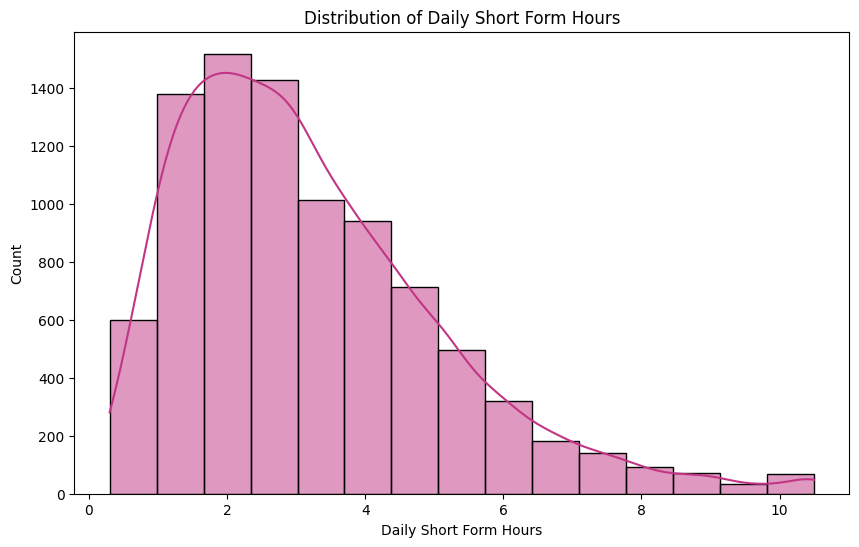

In [27]:
plt.figure(figsize=(10, 6))
sns.histplot(data['daily_short_form_hours'], bins=15, kde=True, color='#C13584')
plt.title('Distribution of Daily Short Form Hours')
plt.xlabel('Daily Short Form Hours')
plt.ylabel('Count')
plt.show()

In [28]:
fig = px.box(
    data,
    x='primary_platform',
    y='daily_short_form_hours',
    color='primary_platform',
    color_discrete_map=platform_colors,
    title='Distribution of Daily Short-Form Video Usage by Platform',
    labels={
        'primary_platform': 'Primary Platform',
        'daily_short_form_hours': 'Daily Short Form Hours',
    },
    height=500,
    width=800

)
fig.show()

In [29]:
fig = px.scatter(
    data,
    x='total_sleep_hours',
    y='daily_short_form_hours',
    opacity=0.3,
    trendline='ols',
    title='Daily Short Form Hours vs. Total Sleep Hours',
    labels={
        'total_sleep_hours': 'Total Sleep Hours',
        'daily_short_form_hours': 'Daily Short Form Hours',
    },
    width=800,
    height=500
)
fig.update_traces(line=dict(color='#C13584'))
fig.show()

In [30]:
fig = px.scatter(
    data,
    x='bedtime_scroll_min',
    y='sustained_attention_span_sec',
    color='dopamine_burnout_index',
    color_continuous_scale='Viridis',
    opacity=0.5,
    trendline='ols',
    title='Relationship Between Bedtime Scrolling and Sustained Attention Span',
    labels={
        'bedtime_scroll_min': 'Bedtime Scroll (Minutes)',
        'sustained_attention_span_sec': 'Sustained Attention Span (Seconds)',
        'dopamine_burnout_index': 'Dopamine Burnout Index',
    },
    width=900,
    height=600
)
fig.update_traces(line=dict(color='#C13584', width=2))

fig.show()

# **Correlation**

In [31]:
correlation_labels = {
    col: col.replace("_", " ").title()
    for col in correlation_matrix.columns
}

correlation_matrix_display = correlation_matrix.rename(
    index=correlation_labels,
    columns=correlation_labels
)

fig = px.imshow(
    correlation_matrix_display,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    aspect="auto",
    labels={
        "x": "Features",
        "y": "Features",
        "color": "Correlation Coefficient"
    }
)

fig.update_layout(
    title=dict(
        text="Correlation Matrix of Numerical Features",
        font=dict(size=22),
        x=0.5,
        xanchor="center"
    ),
    width=1200,
    height=900,
    template="plotly_white",
    xaxis=dict(
        tickangle=-45,
        side="bottom"
    ),
    yaxis=dict(
        autorange="reversed"
    ),
    coloraxis_colorbar=dict(
        title="Correlation Coefficient"
    )
)

fig.show()

In [32]:
corr_pairs = correlation_matrix.unstack().reset_index()
corr_pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']

best_correlations = corr_pairs[corr_pairs['Feature 1'] != corr_pairs['Feature 2']].copy()

best_correlations['temp_key'] = best_correlations.apply(lambda r: "-".join(sorted([r['Feature 1'], r['Feature 2']])), axis=1)
best_correlations = best_correlations.drop_duplicates(subset=['temp_key'])

best_correlations['Abs_Correlation'] = best_correlations['Correlation'].abs()
best_correlations = best_correlations.sort_values(by='Abs_Correlation', ascending=False)

top_correlations = best_correlations.head(20).copy()
top_correlations["Relationship"] = np.where(
    top_correlations["Correlation"] > 0,
    "Positive",
    "Negative"
)
top_correlations["Pair"] = (
    top_correlations["Feature 1"]
    + " ↔ "
    + top_correlations["Feature 2"]
)

plot_data = top_correlations.copy()
plot_data["Pair"] = plot_data["Pair"].str.replace(
    "_", " ", regex=False
)
plot_data = plot_data.sort_values("Correlation")

fig = px.bar(
    plot_data,
    x="Correlation",
    y="Pair",
    color="Relationship",
    color_discrete_map={
        "Positive": "#16A085",
        "Negative": "#E74C3C"
    },
    orientation="h",
    text=plot_data["Correlation"].round(3),
    title="Top 20 Strongest Correlations",
    labels={
        "Correlation": "Correlation Coefficient",
        "Pair": "Feature Pairs",
        "Relationship": "Correlation Type"
    }
)

fig.update_layout(
    template="plotly_white",
    title_x=0.5,
    xaxis=dict(range=[-1, 1]),
    height=800
)

fig.update_traces(
    textposition="outside",
    hovertemplate=(
        "Feature Pair: %{y}<br>"
        "Correlation: %{x:.3f}"
        "<extra></extra>"
    )
)

fig.show()

#**feature selection**

In [33]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

mi_data = data_dirty.copy()

if 'participant_id' in mi_data.columns:
    mi_data = mi_data.drop(columns=['participant_id'])

target_col = 'cognitive_decay_tier'
y = mi_data[target_col]
X = mi_data.drop(columns=[target_col])

for col in X.select_dtypes(include=['object', 'category']).columns:
    X[col] = LabelEncoder().fit_transform(X[col].astype(str))

mi_scores = mutual_info_classif(X, y, random_state=42)

feature_scores = pd.DataFrame({
    'Feature': X.columns,
    'Mutual Information': mi_scores
}).sort_values(by='Mutual Information', ascending=False)

plot_data = feature_scores.head(15).copy()

plot_data["Feature"] = (
    plot_data["Feature"]
    .str.replace("_", " ", regex=False)
    .str.title()
)

fig = px.bar(
    plot_data.sort_values("Mutual Information"),
    x="Mutual Information",
    y="Feature",
    orientation="h",
    text=plot_data.sort_values("Mutual Information")[
        "Mutual Information"
    ].round(3),
    title="Top 15 Features Associated with Cognitive Decay Tier",
    labels={
        "Feature": "Features",
        "Mutual Information": "Mutual Information Score"
    },
    color="Mutual Information",
    color_continuous_scale="Blues",
    template="plotly_white",
    height=650
)

fig.update_traces(
    textposition="outside",
    hovertemplate=(
        "Feature: %{y}<br>"
        "Mutual Information Score: %{x:.3f}"
        "<extra></extra>"
    ),
    cliponaxis=False
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor="center",
        font=dict(size=20)
    ),
    xaxis_title="Mutual Information Score",
    yaxis_title="Features",
    yaxis=dict(categoryorder="total ascending"),
    coloraxis_showscale=False,
    margin=dict(l=20, r=70, t=80, b=50)
)

fig.show()

#**Encoding**

In [34]:
data_encoded = pd.get_dummies(
    data_dirty,
    drop_first=False,
    dtype=int
)

data_encoded.head()

,age,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,...,gender_Male,gender_Non-Binary,primary_platform_Instagram Reels,primary_platform_Snapchat Spotlight,primary_platform_TikTok,primary_platform_YouTube Shorts,cognitive_decay_tier_Acute Brain Rot / Executive Burnout,cognitive_decay_tier_Mild Attentional Strain,cognitive_decay_tier_Normal / Intact Focus,cognitive_decay_tier_Severe Focus Fragmentation
0,27.0,2.4,5.1,11.8,9.0,70.0,7.8,4.0,5.9,74.1,...,0,0,1,0,0,0,0,1,0,0
1,48.0,4.0,11.1,5.4,10.0,90.0,6.1,2.9,6.8,71.6,...,0,0,0,0,1,0,0,1,0,0
2,34.0,3.3,17.5,3.4,13.0,59.0,6.5,3.3,8.1,93.8,...,0,0,1,0,0,0,0,1,0,0
3,30.0,3.6,11.8,5.1,7.0,57.0,6.9,2.2,7.3,84.5,...,1,0,1,0,0,0,0,1,0,0
4,19.0,1.9,17.3,3.5,4.0,30.0,7.2,3.5,6.2,110.2,...,0,0,0,0,0,1,0,0,1,0


# **Data Normalization**

In [35]:
from sklearn.preprocessing import MinMaxScaler

numeric_cols = data_dirty.select_dtypes(include=['float64', 'int64']).columns.tolist()

scaler = MinMaxScaler()

data_normalized = data_dirty.copy()
data_normalized[numeric_cols] = scaler.fit_transform(data_normalized[numeric_cols])

data_normalized[numeric_cols].head()

,age,daily_short_form_hours,avg_clip_duration_sec,swipes_per_minute,scroll_sessions_day,bedtime_scroll_min,total_sleep_hours,multitasking_score,total_screen_time_hours,sustained_attention_span_sec,working_memory_score,task_switch_latency_sec,brain_fog_score,dopamine_burnout_index,attention_retention_pct
0,0.282051,0.205882,0.081395,0.541899,0.296296,0.388889,0.716667,0.333333,0.238095,0.454296,0.711111,0.303333,0.288889,0.348663,0.465681
1,0.820513,0.362745,0.313953,0.184358,0.333333,0.500000,0.433333,0.211111,0.309524,0.437113,0.655556,0.253333,0.422222,0.317647,0.447730
2,0.461538,0.294118,0.562016,0.072626,0.444444,0.327778,0.500000,0.255556,0.412698,0.589691,0.622222,0.210000,0.377778,0.326203,0.604013
3,0.358974,0.323529,0.341085,0.167598,0.222222,0.316667,0.566667,0.133333,0.349206,0.525773,0.633333,0.226667,0.377778,0.331551,0.538543
4,0.076923,0.156863,0.554264,0.078212,0.111111,0.166667,0.616667,0.277778,0.261905,0.702405,0.922222,0.170000,0.311111,0.139037,0.720169
